# 03 Data: the person-month table

Every hazard model is fitted on a **person-month table**: one row per customer per month at risk, instead of one row
per customer (Allison, 1982; Singer & Willett, 1993). This notebook builds it from the shared cleaned split and
checks it. The code lives in `prep.py` so that `04` and `05` build exactly the same table.

**Run `report/01-Data.ipynb` first**: it makes `data/processed/taiwan-{train,validation,test}.csv`.

**Where the code comes from:** the person-period layout is the standard one (Allison, 1982), and is explained for
Python by [Wheeler (2020)](https://andrewpwheeler.com/2020/09/26/discrete-time-survival-models-in-python/). His code
has no licence and expands durations with fixed covariates, whereas ours change every month, so `prep.py` is my own.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import prep

wide = prep.load_split()                  # train and validation only: the test set is not touched here
{part: df.shape for part, df in wide.items()}

{'train': (17997, 24), 'validation': (5999, 24)}

## 1. The timeline

The raw columns count backwards (`PAY_1` is September, `PAY_6` is April). I number time forwards:

| t | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| Month | Apr | May | Jun | Jul | Aug | Sep | **Oct** |
| Status column | `PAY_6` | `PAY_5` | `PAY_4` | `PAY_3` | `PAY_2` | `PAY_1` | (the label) |

The choices (from `../research/02-model-choices.md`):

* **Event:** 2 or more months behind (`PAY >= 2`) in June to September, a proxy because there is no default date;
  the real default label in October.
* **Risk set:** everyone, every month. Customers already behind are kept, with last month's status as a covariate.
* **Lag:** covariates come from the month before the event (month $t-1$ predicts month $t$), so a month's own
  status never predicts itself.
* **Months modelled:** June to October ($t = 3..7$). The payment ratio needs the previous month's bill, so April and
  May only supply covariates.

So each customer has five rows, and **the October row is the one scored**: September covariates, October default.

In [2]:
long = prep.long_table(wide["train"])
long.loc[long.index.unique()[:2]]         # the first two training customers, five rows each

,t,event,status_lag,util_lag,payratio_lag,log_limit,age,SEX,EDUCATION,MARRIAGE
ID,,,,,,,,,,
1,3,0,-2,0.000000,1.000000,9.903488,24,2,2,1
1,4,0,-1,0.000000,1.000000,9.903488,24,2,2,1
1,5,1,-1,0.034450,1.000000,9.903488,24,2,2,1
1,6,1,2,0.155100,1.000000,9.903488,24,2,2,1
1,7,1,2,0.195650,0.000000,9.903488,24,2,2,1
2,3,0,0,0.028792,0.000000,11.695247,26,2,2,2
2,4,0,0,0.027267,0.289436,11.695247,26,2,2,2
2,5,1,0,0.022350,0.305623,11.695247,26,2,2,2
2,6,0,2,0.014375,0.372856,11.695247,26,2,2,2


## 2. Checks

In [3]:
assert (long.groupby(level=0).size() == 5).all()                                   # five rows per customer
assert (prep.october(long)["event"] == wide["train"][prep.Y]).all()                # October row = the label
assert long[prep.CONTINUOUS].notna().all().all()
print("training rows:", len(long), "customers:", long.index.nunique())

training rows: 89985 customers: 17997


## 3. Event rate by month

Only October is a real default. June to September use the proxy, so the earlier months answer a slightly different
question ("falls 2+ months behind") from October ("defaults"). The model gives each month its own intercept, so the
different levels are absorbed; whether the shared coefficients suit both questions is tested in `04`.

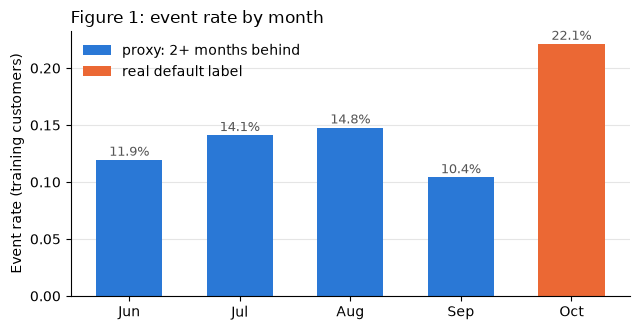

,rate,events
Jun,0.119,2149
Jul,0.141,2539
Aug,0.148,2659
Sep,0.104,1873
Oct,0.221,3981


In [4]:
rates = long.groupby("t")["event"].agg(rate="mean", events="sum")
rates.index = ["Jun", "Jul", "Aug", "Sep", "Oct"]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(rates.index[:-1], rates["rate"].iloc[:-1], width=0.6, color="#2a78d6", label="proxy: 2+ months behind")
ax.bar(rates.index[-1:], rates["rate"].iloc[-1:], width=0.6, color="#eb6834", label="real default label")
for x, r in enumerate(rates["rate"]):
    ax.annotate(f"{r:.1%}", (x, r), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color="#555555")
ax.set_ylabel("Event rate (training customers)")
ax.set_title("Figure 1: event rate by month", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
rates.round(3)

## 4. The design matrix

`prep.person_months` turns the table into the model's design matrix $X$ (lecture 02.1): status and the demographics
become 0/1 columns (one-hot, dropping a reference code: `-1` "paid on time" for status, `1` for the others, the same
references as `Oscar/prep.py`); each month gets its own 0/1 column, which gives each month its own baseline hazard
$\alpha_t$; the four continuous columns are standardised with the **training** rows' mean and standard deviation.

In [5]:
pm = prep.person_months(wide)
X = pm["train"]
print(len(prep.features(X)), "features:", prep.features(X))
X.describe().T[["mean", "std", "min", "max"]].round(2)

19 features: ['util_lag', 'payratio_lag', 'log_limit', 'age', 'status_lag_-2', 'status_lag_0', 'status_lag_1', 'status_lag_2', 'status_lag_3', 'SEX_2', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_2', 'MARRIAGE_3', 't_4', 't_5', 't_6', 't_7']


,mean,std,min,max
t,5.00,1.41,3.00,7.00
event,0.15,0.35,0.00,1.00
util_lag,0.00,1.00,-3.76,2.95
payratio_lag,-0.00,1.00,-0.91,1.32
log_limit,-0.00,1.00,-2.62,2.05
age,-0.00,1.00,-1.57,4.71
status_lag_-2,0.13,0.34,0.00,1.00
status_lag_0,0.53,0.50,0.00,1.00
status_lag_1,0.02,0.15,0.00,1.00
status_lag_2,0.11,0.31,0.00,1.00


## 5. What this table can and cannot do

* Rows from the same customer are **not independent** (lecture 02.2), so the customer, not the row, is the unit for
  cross-validation and the bootstrap in `04` and `05`.
* The month dummies carry much of the signal; the October dummy is estimated from the October rows only.
* There is no account age, so $t$ is calendar month, not time since the account opened.

Next: `04-hazard-models.ipynb`.